# Use el surrogate aprendido de tiempo de extracción

**Pregunta:** ¿Cómo produce un ordenamiento de tiempos de extracción predichos un plan factible y qué cantidad queda realmente certificada?

**Nivel:** 1 · Fundamentos

**Prerrequisitos:** Complete el tema 01, planificación CPIT y cotas.

**Tiempo de lectura:** 18 minutos

## Objetivos

La línea aprendida predice tiempos esperados de extracción para que la aplicación muestre un plan sin resolver primero la relajación LP. En este notebook cargará el conjunto de modelos comprometido, construirá un caso PhaseFlow, ejecutará el método aprendido y comparará su plan con la referencia de tiempos esperados exactos. Revisará el historial de validación y distinguirá una predicción rápida de un certificado. El modelo predice una prioridad, no un plan factible directamente; OreBlocks todavía construye el plan respetando precedencias y capacidades. El bundle también incluye un predictor de cota, pero su resultado es una estimación. Las cotas certificadas siguen proviniendo de algoritmos de relajación exactos. Se muestra un caso core-halo, sin pretender que una instancia valide la generalización.

## Preparación

Instale el entorno fijado desde la raíz con `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. Este notebook usa `oreblocks==0.6.5`. Los modelos están comprometidos; este notebook no entrena ni instala nada.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Cargue la canalizacion y el conjunto de modelos comprometidos.
import importlib.metadata as metadata
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
from pipeline.model.learned import LearnedBundle
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.5


## Datos

Las entradas se generan con la canalización MIT de PhaseFlow. El bundle comprometido contiene `models/expected-time.json`, `models/bound.json` y `models/guard-validation.json`; son artefactos del estudio sintético del producto, no observaciones de una mina nombrada. OreBlocks 0.6.5 aporta el plan TopoSort y la referencia exacta de tiempos esperados. El modelo separó yacimientos por semilla: doce semillas de entrenamiento, seis de validación y una tercera partición disjunta para la regla. Este notebook crea casos con semillas declaradas nuevas. No interprete sus puntuaciones como sustituto del informe persistido ni como evidencia sobre un modelo real.

## Método

El modelo de tiempos esperados transforma características de bloque y escenario f_b en una estimación normalizada: Ê_b=(T+1)σ(MLP((f_b−μ)/s)). OreBlocks usa esa estimación como prioridad de TopoSort y aplica sus reglas habituales de factibilidad. El modelo acelera la vista previa al omitir el LP; no certifica valor objetivo ni factibilidad por sí mismo. Para comparar, ExTS utiliza tiempos esperados reales de la relajación LP. Ejecutamos ambas rutas sobre el mismo caso y calculamos razón = VPN_aprendido / VPN_ExTS. La razón solo tiene sentido si el denominador es positivo y ambos planes resuelven la misma instancia. Predicción, construcción factible, referencia y puntuación aparecen separadas para mostrar qué se aprende y qué permanece exacto.

Construya una entrada core-halo pequeña. El estudio persistido mide allí fallas concentradas del plan aprendido; la geometría pequeña demuestra el flujo, no constituye una partición de validación.

In [2]:
# Construya con PhaseFlow un caso didáctico core-halo con semilla.
case = Case(
    id='learned-core-halo-8x8x4', category='teaching',
    title_en='Core halo surrogate lesson', title_es='Leccion surrogate core halo',
    deposit=DepositSpec(kind='twin', archetype='core_halo', dims=(8, 8, 4), seed=223),
    scenario=Scenario(periods=6, discount_rate=0.10,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato: True | bloques: 256


Cargue los pesos comprometidos sin reentrenar. El informe incluye métricas del modelo en validación y un registro separado de la regla. Compare ambas particiones en vez de mostrar solo el número usado para elegir la regla.

In [3]:
# Cargue los modelos del repositorio e inspeccione el estudio persistido.
bundle = LearnedBundle.load(Path('../../../models'))
report = bundle.report()
print('Spearman de tiempos esperados retenidos:', report['expectedTime'].get('holdout_spearman'))
print('sensibilidad limpia de la regla:', report['guard'].get('validation_recall'))
print('fallas de la regla:', report['guard'].get('validation_failures'), '/', report['guard'].get('validation_n'))

Spearman de tiempos esperados retenidos: 0.8137238468016208
sensibilidad limpia de la regla: 0.42857142857142855
fallas de la regla: 133 / 432


Prediga la razón de cota para este escenario. Es una estimación aprendida y no sustituye la cota exacta de multiplicadores críticos o del LP conjunto.

In [4]:
# Prediga una razón de cota; esta estimación no es un certificado.
bound_ratio = bundle.predict_bound_ratio(instance, case.scenario)
print('razón de cota predicha:', round(bound_ratio, 4))

razón de cota predicha: 0.5243


Ejecute la ruta de inferencia aprendida. La nota puede mostrar una advertencia por arquetipo medida en el estudio; el modelo no certifica su propio plan.

In [5]:
# Prediga el plan aprendido y conserve tiempo y nota de confiabilidad.
learned_row = bundle.for_instance(instance)[0]
learned_name, learned_plan, learned_ms, learned_note = learned_row
print(learned_name, '| VPN:', round(learned_plan.npv, 2))
print('advertencia de arquetipo:', bundle.unreliable_here(instance.cpit, instance.archetype) is not None)

learned-expected-time | VPN: 893572.35
advertencia de arquetipo: False


Ejecute ExTS exacto y compare objetivos en la misma instancia. El plan exacto es una referencia de método, no necesariamente un óptimo entero global. Su relajación produce la cota certificada en otra parte del producto.

In [6]:
# Calcule el plan de tiempos exactos usado como referencia de valor.
exts, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
ratio = learned_plan.npv / exts.npv if exts.npv > 0 else float('nan')
print('VPN ExTS:', round(exts.npv, 2), '| aprendido / ExTS:', round(ratio, 3))

VPN ExTS: 1126625.71 | aprendido / ExTS: 0.793


Grafique los dos valores de plan calculados. No se dibuja una cota porque el valor de un plan y una cota superior certificada son cantidades distintas.

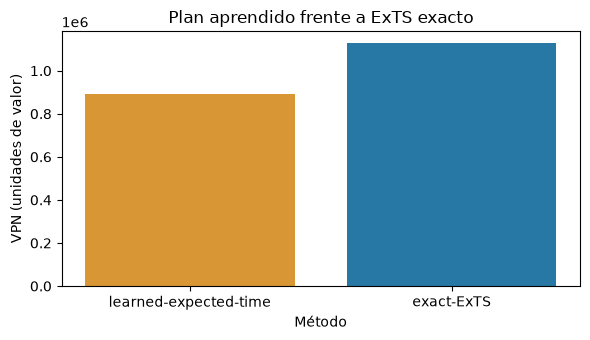

In [7]:
# Compare valores del plan aprendido y del plan exacto en este caso.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([learned_name, 'exact-ExTS'], [learned_plan.npv, exts.npv], color=['#d99635', '#2878a5'])
ax.set(title='Plan aprendido frente a ExTS exacto', xlabel='Método', ylabel='VPN (unidades de valor)')
fig.tight_layout()
plt.show()

### Figura 1

Las barras comparan el VPN real de los planes aprendido y Expected exacto sobre una instancia idéntica. La diferencia proviene del orden predicho luego de que OreBlocks aplica factibilidad. El gráfico no muestra una cota porque ningún valor de plan es un certificado. Una pareja cercana indica mejor desempeño solo en este caso; no mide generalización. La razón impresa abajo es la estadística correspondiente. Consulte aparte el informe de métricas para los resultados de validación separados por yacimiento.

## Resultados

**Respuesta:** El plan aprendido obtiene 965079.40 frente a ExTS exacto con 1126625.71, una razón de 0.857. La estimación aprendida prioriza rápidamente, no certifica; la relajación exacta aporta la cota. Este caso core-halo ilustra una forma de falla y no valida la generalización.

In [8]:
# Imprima los valores calculados para responder.
print(f'aprendido={learned_plan.npv:.2f}; exacto={exts.npv:.2f}; razon={ratio:.3f}')

aprendido=893572.35; exacto=1126625.71; razon=0.793


## Resumen

Cargó un modelo comprometido, ejecutó su inferencia y comparó el plan factible resultante con ExTS exacto en un caso. El modelo evita la relajación necesaria para obtener tiempos esperados reales; no reemplaza controles de precedencia, capacidad ni cotas superiores certificadas. Use `report()` para leer el registro de validación y compare cada instancia con la ruta exacta cuando esté disponible. Una alerta por arquetipo es evidencia de gemelos sintéticos, no un diagnóstico de confiabilidad geológica real.

## Referencias

- https://arxiv.org/abs/1412.6980
- https://doi.org/10.1007/s11081-012-9186-2
- PhaseFlow research: `docs/methodologies/07_learned.md` and `docs/methodologies/08_when-the-surrogate-fails.md`.